# Initial Checks and Directory Adjustments

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/bochinski/tf-smoe-master/LICENSE
/kaggle/input/bochinski/tf-smoe-master/README.md
/kaggle/input/bochinski/tf-smoe-master/plotter.py
/kaggle/input/bochinski/tf-smoe-master/samples.ipynb
/kaggle/input/bochinski/tf-smoe-master/utils.py
/kaggle/input/bochinski/tf-smoe-master/smoe.py
/kaggle/input/bochinski/tf-smoe-master/train_model.py
/kaggle/input/bochinski/tf-smoe-master/logger.py
/kaggle/input/bochinski/tf-smoe-master/ops/special_math_ops.py
/kaggle/input/bochinski/tf-smoe-master/doc/fig3.png
/kaggle/input/bochinski/tf-smoe-master/doc/fig1.png
/kaggle/input/bochinski/tf-smoe-master/doc/different_k.png
/kaggle/input/bochinski/tf-smoe-master/doc/fig2.png
/kaggle/input/bochinski/tf-smoe-master/doc/fig4.png
/kaggle/input/bochinski/tf-smoe-master/data/demo.png
/kaggle/input/bochinski/tf-smoe-master/data/lena.png
/kaggle/input/images/Grass_sq.png
/kaggle/input/images/Nature_sq.png
/kaggle/input/images/Gradient_sq.png
/kaggle/input/images/Mixed_sq.png
/kaggle/input/images/SharpE

In [2]:
!git clone https://github.com/bochinski/tf-smoe.git
%cd tf-smoe


Cloning into 'tf-smoe'...
remote: Enumerating objects: 26, done.
remote: Total 26 (delta 0), reused 0 (delta 0), pack-reused 26 (from 1)
Receiving objects: 100% (26/26), 2.71 MiB | 31.21 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/kaggle/working/tf-smoe


In [3]:
!cp -r /kaggle/input/bochinski/tf-smoe-master /kaggle/working/
%cd /kaggle/working/tf-smoe-master


/kaggle/working/tf-smoe-master


In [4]:
!mkdir -p data

In [5]:
!cp /kaggle/input/images/Gradient_sq.png data/
!cp /kaggle/input/images/Grass_sq.png data/
!cp /kaggle/input/images/Nature_sq.png data/
!cp /kaggle/input/images/Mixed_sq.png data/
!cp /kaggle/input/images/SharpEdges_sq.png data/

In [6]:
!mkdir -p results

In [7]:
!ls /kaggle/working

__notebook__.ipynb  tf-smoe  tf-smoe-master


In [8]:
%cd /kaggle/working/tf-smoe-master

/kaggle/working/tf-smoe-master


# Tensorflow & SSIM Version
Tensorflow's version needs to be adjusted since Kaggle uses v2, whilst SMoE uses v1.

First smoe.py needs to be fixed, after that, also train_model.py needs to be fixed.

In [9]:
%cd /kaggle/working/tf-smoe-master

# Replace the old import with the new one
!sed -i "s/from skimage.measure import compare_ssim/from skimage.metrics import structural_similarity as compare_ssim/" plotter.py

/kaggle/working/tf-smoe-master


In [10]:
%cd /kaggle/working/tf-smoe-master

import os

path = "smoe.py"
with open(path, "r") as f:
    txt = f.read()

if "disable_v2_behavior" not in txt:
    txt = txt.replace(
        "import tensorflow as tf",
        "import tensorflow as tf\n"
        "tf.compat.v1.disable_v2_behavior()\n"
        "tf.compat.v1.disable_eager_execution()\n"
        "# use TensorFlow 1.x style API via compat.v1\n"
        "tf = tf.compat.v1"
    )
    with open(path, "w") as f:
        f.write(txt)

print("Patched smoe.py to use TensorFlow 1.x compat mode.")

/kaggle/working/tf-smoe-master
Patched smoe.py to use TensorFlow 1.x compat mode.


In [11]:
%cd /kaggle/working/tf-smoe-master

import os

path = "train_model.py"
with open(path, "r") as f:
    txt = f.read()

if "disable_v2_behavior" not in txt:
    txt = txt.replace(
        "import tensorflow as tf",
        "import tensorflow as tf\n"
        "tf.compat.v1.disable_v2_behavior()\n"
        "tf.compat.v1.disable_eager_execution()\n"
        "# use TensorFlow 1.x style API via compat.v1\n"
        "tf = tf.compat.v1"
    )
    with open(path, "w") as f:
        f.write(txt)

print("Patched train_model.py to use TensorFlow 1.x compat mode.")

/kaggle/working/tf-smoe-master
Patched train_model.py to use TensorFlow 1.x compat mode.


# Grayscale Downsampling
In order for basic SMoE to work properly, the images need to be grayscaled, this does not affect PSNR and SSIM parameters.

In [12]:
from skimage.io import imread, imsave
from skimage.color import rgb2gray
import numpy as np
import os, glob

os.chdir("/kaggle/working/tf-smoe-master")

os.makedirs("data", exist_ok=True)

for path in glob.glob("data/*.png"):
    img = imread(path)
    # If RGB or RGBA, make it grayscale
    if img.ndim == 3:
        # drop alpha if present
        if img.shape[2] == 4:
            img = img[..., :3]
        gray = rgb2gray(img)   # float64 in [0, 1]
    else:
        gray = img

    # Ensure 2D uint8 image in [0, 255]
    if gray.dtype != np.uint8:
        gray_u8 = (gray * 255).clip(0, 255).astype(np.uint8)
    else:
        gray_u8 = gray

    base = os.path.splitext(os.path.basename(path))[0]
    out_path = f"data/{base}_gray.png"
    imsave(out_path, gray_u8)
    print(f"Saved {out_path} (dtype={gray_u8.dtype}, min={gray_u8.min()}, max={gray_u8.max()})")


Saved data/Gradient_sq_gray.png (dtype=uint8, min=0, max=121)
Saved data/Nature_sq_gray.png (dtype=uint8, min=0, max=255)
Saved data/lena_gray.png (dtype=uint8, min=25, max=245)
Saved data/demo_gray.png (dtype=uint8, min=27, max=215)
Saved data/Mixed_sq_gray.png (dtype=uint8, min=0, max=255)
Saved data/SharpEdges_sq_gray.png (dtype=uint8, min=0, max=201)
Saved data/Grass_sq_gray.png (dtype=uint8, min=0, max=171)


# model_train.py Fixes

In [13]:
%cd /kaggle/working/tf-smoe-master

path = "train_model.py"

with open(path, "r") as f:
    txt = f.read()

old_block = """
    # --- Save plain reconstruction image for external use ---
    import os
    import numpy as np
    from skimage.io import imsave

    recon = smoe.get_reconstruction()  # float image in [0,1]
    recon_uint8 = (recon * 255).clip(0, 255).astype(np.uint8)
    out_path = os.path.join(results_path, "reconstruction.png")
    imsave(out_path, recon_uint8)
    print("Saved reconstruction image to", out_path)
"""

new_block = """
    # --- Save plain reconstruction image for external use ---
    from skimage.io import imsave

    recon = smoe.get_reconstruction()  # float image in [0,1]
    recon_uint8 = (recon * 255).clip(0, 255).astype(np.uint8)
    out_path = os.path.join(results_path, "reconstruction.png")
    imsave(out_path, recon_uint8)
    print("Saved reconstruction image to", out_path)
"""

if old_block not in txt:
    print("WARNING: old_block pattern not found. You may already have edited this part; in that case, open train_model.py and just delete 'import os' and 'import numpy as np' from inside main().")
else:
    txt = txt.replace(old_block, new_block)
    with open(path, "w") as f:
        f.write(txt)
    print("Fixed train_model.py: removed inner imports of os / numpy from main().")


/kaggle/working/tf-smoe-master


In [14]:
%%writefile train_model.py
# ---------------------------------------------------------------------
# Modified train_model.py for SMoE on Kaggle
# - TF 1.x compat mode
# - Saves plain reconstruction.png after training
# ---------------------------------------------------------------------

# for execution without a display
# import matplotlib as mpl
# mpl.use('Agg')

import argparse
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import os
import shutil
from skimage.io import imsave

# --- TensorFlow 1.x compatibility ---
tf.compat.v1.disable_v2_behavior()
tf.compat.v1.disable_eager_execution()
tf = tf.compat.v1

from smoe import Smoe
from plotter import ImagePlotter, LossPlotter
from logger import ModelLogger
from utils import save_model, load_params


def main(
    image_path,
    results_path,
    iterations,
    validation_iterations,
    kernels_per_dim,
    params_file,
    l1reg,
    base_lr,
    batches,
    checkpoint_path,
    lr_div,
    lr_mult,
    disable_train_pis,
    disable_train_gammas,
    radial_as,
    quiet,
):
    # --- load image ---
    orig = plt.imread(image_path)
    if orig.dtype == np.uint8:
        orig = orig.astype(np.float32) / 255.0

    # --- init params ---
    if params_file is not None:
        init_params = load_params(params_file)
    else:
        init_params = None

    # --- results dir ---
    if results_path is not None:
        if os.path.exists(results_path):
            shutil.rmtree(results_path)
        os.makedirs(results_path, exist_ok=True)

    # --- plotters + logger ---
    loss_plotter = LossPlotter(path=results_path + "/loss.png", quiet=quiet)
    image_plotter = ImagePlotter(
        path=results_path,
        options=["orig", "reconstruction", "gating", "pis_hist"],
        quiet=quiet,
    )
    logger = ModelLogger(path=results_path)

    # --- SMoE model ---
    smoe = Smoe(
        orig,
        kernels_per_dim,
        init_params=init_params,
        train_pis=not disable_train_pis,
        train_gammas=not disable_train_gammas,
        radial_as=radial_as,
        start_batches=batches,
    )

    # --- optimizers ---
    optimizer1 = tf.train.AdamOptimizer(base_lr)
    optimizer2 = tf.train.AdamOptimizer(base_lr / lr_div)
    optimizer3 = tf.train.AdamOptimizer(base_lr * lr_mult)

    # optimizers have to be set before restore
    smoe.set_optimizer(optimizer1, optimizer2, optimizer3)

    # --- optional checkpoint restore ---
    if checkpoint_path is not None:
        smoe.restore(checkpoint_path)

    # --- training ---
    smoe.train(
        iterations,
        val_iter=validation_iterations,
        pis_l1=l1reg,
        callbacks=[loss_plotter.plot, image_plotter.plot, logger.log],
    )

    # --- save plain reconstruction image for tiling code ---
    recon = smoe.get_reconstruction()  # float array in [0,1]
    recon_uint8 = (recon * 255.0).clip(0, 255).astype(np.uint8)
    recon_path = os.path.join(results_path, "reconstruction.png")
    imsave(recon_path, recon_uint8)
    print("Saved reconstruction image to", recon_path)

    # --- save parameters ---
    save_model(smoe, results_path + "/params_best.pkl", best=True)
    save_model(smoe, results_path + "/params_last.pkl", best=False)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument(
        "-i", "--image_path", type=str, required=True, help="input image"
    )
    parser.add_argument(
        "-r", "--results_path", type=str, required=True, help="results path"
    )
    parser.add_argument(
        "-n",
        "--iterations",
        type=int,
        default=100,
        help="number of iterations",
    )
    parser.add_argument(
        "-v",
        "--validation_iterations",
        type=int,
        default=100,
        help="number of iterations between validations",
    )
    parser.add_argument(
        "-k",
        "--kernels_per_dim",
        type=int,
        default=12,
        help="number of kernels per dimension",
    )
    parser.add_argument(
        "-p",
        "--params_file",
        type=str,
        default=None,
        help="parameter file for model initialization",
    )
    parser.add_argument(
        "-reg",
        "--l1reg",
        type=float,
        default=0.0,
        help="l1 regularization for pis",
    )
    parser.add_argument(
        "-lr",
        "--base_lr",
        type=float,
        default=0.001,
        help="base learning rate",
    )
    parser.add_argument(
        "-b",
        "--batches",
        type=int,
        default=1,
        help=(
            "number of batches to split the training into "
            "(will be automatically reduced when number of pis drops)"
        ),
    )
    parser.add_argument(
        "-c",
        "--checkpoint_path",
        type=str,
        default=None,
        help=(
            "path to a checkpoint file to continue the training. "
            "EXPERIMENTAL."
        ),
    )
    parser.add_argument(
        "-d", "--lr_div", type=float, default=100.0, help="div for pis lr"
    )
    parser.add_argument(
        "-m", "--lr_mult", type=float, default=1000.0, help="mult for a lr"
    )
    parser.add_argument(
        "-dp",
        "--disable_train_pis",
        type=bool,
        default=False,
        help="disable training of pis",
    )
    parser.add_argument(
        "-dg",
        "--disable_train_gammas",
        type=bool,
        default=False,
        help="disable training of gammas",
    )
    parser.add_argument(
        "-ra",
        "--radial_as",
        type=bool,
        default=False,
        help="use radial kernel (no steering)",
    )
    parser.add_argument(
        "-q",
        "--quiet",
        type=bool,
        default=False,
        help="do not display plots",
    )

    args = parser.parse_args()
    main(**vars(args))


Overwriting train_model.py


# Tiling, Reconstruction and Compression
SMoE is a very heavy algorithm, for a 1280x1280 image the RAM should be of approximately 70GB of RAM, hence, we need to reduce the images into smaller tiles and then reconstructing it again.

During this procedure, every single tile is compressed through SMoE.

In [15]:
import os
import math
import shutil
import glob
import subprocess

import numpy as np
from skimage.io import imread, imsave
from skimage.transform import resize

# ---------------------------------------------------------
# Helper: list image files in a directory
# ---------------------------------------------------------
def list_images_in_dir(d):
    exts = ("*.png","*.jpg","*.jpeg","*.tif","*.tiff")
    files = []
    for e in exts:
        files.extend(glob.glob(os.path.join(d, e)))
    return sorted(files)

# ---------------------------------------------------------
# Helper: choose reconstructed tile image from a tile results dir
# (now just use reconstruction.png written by train_model.py)
# ---------------------------------------------------------
def pick_recon_image(results_dir, tile_size):
    path = os.path.join(results_dir, "reconstruction.png")
    if os.path.exists(path):
        return path, "explicit_reconstruction"
    else:
        return None, "missing_reconstruction"

# ---------------------------------------------------------
# Main function: process one image with SMoE tiling
# ---------------------------------------------------------
def process_image_with_smoe_tiled(
    image_path,
    tile_size=512,
    overlap=64,
    kernels_per_dim=32,
    batches=64,     # <<---- new: control memory
):
    """
    Tiled SMoE compression for a single image.

    - image_path: path to grayscale, square image (e.g. data/Gradient_sq_gray.png)
    - tile_size, overlap: tiling parameters
    - kernels_per_dim: passed to train_model.py
    - batches: --batches argument for train_model.py (higher -> less memory)
    """
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")

    basename = os.path.splitext(os.path.basename(image_path))[0]

    # Per-image directories
    tiles_dir = os.path.join("data", "tiles", basename)
    results_tiles_root = os.path.join("results_tiles", basename)
    os.makedirs("results", exist_ok=True)

    # Clean ONLY the previous outputs for THIS image
    if os.path.exists(tiles_dir):
        shutil.rmtree(tiles_dir)
    if os.path.exists(results_tiles_root):
        shutil.rmtree(results_tiles_root)
    recon_path = os.path.join("results", f"{basename}_reconstructed.png")
    if os.path.exists(recon_path):
        os.remove(recon_path)

    os.makedirs(tiles_dir, exist_ok=True)
    os.makedirs(results_tiles_root, exist_ok=True)

    # Load source image (grayscale, square)
    img = imread(image_path)
    if img.ndim != 2:
        raise RuntimeError(f"Expected grayscale 2D, got {img.shape} for {image_path}")
    H, W = img.shape
    if H != W:
        raise RuntimeError(f"Expected square image, got {img.shape} for {image_path}")
    print(f"[{basename}] Loaded image {image_path} with shape {img.shape}")

    # Tiling grid
    step = tile_size - overlap
    nx = math.ceil((W - overlap) / step)
    ny = math.ceil((H - overlap) / step)

    coords = []
    for j in range(ny):
        top = j * step
        for i in range(nx):
            left = i * step
            if left + tile_size > W:
                left = W - tile_size
            if top + tile_size > H:
                top = H - tile_size
            coords.append((top, left, j, i))
    # remove duplicates, keep order
    coords = list(dict.fromkeys(coords))
    print(f"[{basename}] Will process {len(coords)} tiles (nx={nx}, ny={ny}), tile_size={tile_size}, overlap={overlap}")

    # Precompute blending window
    win1d = np.hanning(tile_size)
    win2d = np.outer(win1d, win1d).astype(np.float32)

    accum = np.zeros((H, W), dtype=np.float32)
    weight = np.zeros((H, W), dtype=np.float32)

    # Loop over tiles
    for top, left, ty, tx in coords:
        tile = img[top:top+tile_size, left:left+tile_size]
        tile_name = f"tile_r{ty}_c{tx}"

        # Save tile
        tile_path = os.path.join(tiles_dir, f"{tile_name}.png")
        imsave(tile_path, tile.astype(np.uint8))

        # Per-tile results dir
        tile_results = os.path.join(results_tiles_root, tile_name)
        os.makedirs(tile_results, exist_ok=True)

        print(f"[{basename}] Running SMoE on {tile_name} at {tile_path}")
        cmd = [
            "python", "train_model.py",
            "--image_path", tile_path,
            "--results_path", tile_results,
            "--kernels_per_dim", str(kernels_per_dim),
            "--batches", str(batches),
            "--quiet", "1",
        ]
        proc = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        print("\n".join(proc.stdout.splitlines()[-10:]))

        # Pick reconstructed tile image
        recon_file, reason = pick_recon_image(tile_results, tile_size)
        if recon_file is None:
            raise FileNotFoundError(
                f"[{basename}] No reconstructed image found in {tile_results}"
            )
        print(f"[{basename}] Selected recon file for {tile_name}: {recon_file} (reason={reason})")

        recon_img = imread(recon_file)
        # If color, collapse to luminance-ish
        if recon_img.ndim == 3:
            recon_img = (0.299 * recon_img[..., 0] +
                         0.587 * recon_img[..., 1] +
                         0.114 * recon_img[..., 2]).astype(np.float32)
        else:
            recon_img = recon_img.astype(np.float32)

        # If shape != (tile_size, tile_size), crop or resize
        if recon_img.shape != (tile_size, tile_size):
            print(f"[{basename}] WARNING: recon tile shape {recon_img.shape} != ({tile_size},{tile_size}), resizing/cropping.")
            h, w = recon_img.shape
            if h >= tile_size and w >= tile_size:
                topc = (h - tile_size) // 2
                leftc = (w - tile_size) // 2
                recon_img = recon_img[topc:topc+tile_size, leftc:leftc+tile_size]
            else:
                resized = resize(recon_img, (tile_size, tile_size), anti_aliasing=True)
                recon_img = (resized * 255).clip(0, 255).astype(np.float32)

        # Blend into accumulator
        weighted = recon_img * win2d
        accum[top:top+tile_size, left:left+tile_size] += weighted
        weight[top:top+tile_size, left:left+tile_size] += win2d

    # Final reconstruction
    eps = 1e-8
    reconstructed = (accum / (weight + eps)).clip(0, 255).astype(np.uint8)
    recon_path = os.path.join("results", f"{basename}_reconstructed.png")
    imsave(recon_path, reconstructed)
    print(f"[{basename}] Saved final reconstruction to {recon_path}")
    return recon_path


# ---------------------------------------------------------
# Run the pipeline for all 5 images
# ---------------------------------------------------------
images = [
    "data/Gradient_sq_gray.png",
    "data/Grass_sq_gray.png",
    "data/Nature_sq_gray.png",
    "data/SharpEdges_sq_gray.png",
    "data/Mixed_sq_gray.png",
]

for img_path in images:
    print("\n============================")
    print("Processing:", img_path)
    print("============================")
    out = process_image_with_smoe_tiled(
        img_path,
        tile_size=512,
        overlap=64,
        kernels_per_dim=32,
        batches=64,      # increase to 80/100 if you still OOM
    )
    print("Reconstructed image:", out)



Processing: data/Gradient_sq_gray.png
[Gradient_sq_gray] Loaded image data/Gradient_sq_gray.png with shape (1280, 1280)
[Gradient_sq_gray] Will process 9 tiles (nx=3, ny=3), tile_size=512, overlap=64
[Gradient_sq_gray] Running SMoE on tile_r0_c0 at data/tiles/Gradient_sq_gray/tile_r0_c0.png
Instructions for updating:
non-resource variables are not supported in the long term
I0000 00:00:1763123549.946506      68 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
I0000 00:00:1763123550.117642      68 mlir_graph_optimization_pass.cc:401] MLIR V1 optimization pass is not enabled
Model saved in file: results_tiles/Gradient_sq_gray/tile_r0_c0/checkpoints/00000000_model.ckpt
Model saved in file: results_tiles/Gradient_sq_gray/tile_r0_c0/checkpoints/00000100_model.ckpt
end loss/mse:  6.561977656360796e-06 / 0.42669259617105126 @iter:  100
best loss/ms

/usr/local/lib/python3.11/dist-packages/skimage/_shared/utils.py:328: UserWarning: data/tiles/Grass_sq_gray/tile_r0_c1.png is a low contrast image
  return func(*args, **kwargs)


I0000 00:00:1763124703.821266     908 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
I0000 00:00:1763124703.978396     908 mlir_graph_optimization_pass.cc:401] MLIR V1 optimization pass is not enabled
/usr/local/lib/python3.11/dist-packages/skimage/_shared/utils.py:328: UserWarning: results_tiles/Grass_sq_gray/tile_r0_c1/reconstruction.png is a low contrast image
  return func(*args, **kwargs)
Model saved in file: results_tiles/Grass_sq_gray/tile_r0_c1/checkpoints/00000000_model.ckpt
Model saved in file: results_tiles/Grass_sq_gray/tile_r0_c1/checkpoints/00000100_model.ckpt
end loss/mse:  0.0002240572205778335 / 14.56932078115642 @iter:  100
best loss/mse:  0.0002240572205778335 / 14.56932078115642
Saved reconstruction image to results_tiles/Grass_sq_gray/tile_r0_c1/reconstruction.png
[Grass_sq_gray] Selected recon file for tile_r0_c1: resu

/usr/local/lib/python3.11/dist-packages/skimage/_shared/utils.py:328: UserWarning: data/tiles/Grass_sq_gray/tile_r0_c2.png is a low contrast image
  return func(*args, **kwargs)


I0000 00:00:1763124819.084719     992 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
I0000 00:00:1763124819.242271     992 mlir_graph_optimization_pass.cc:401] MLIR V1 optimization pass is not enabled
/usr/local/lib/python3.11/dist-packages/skimage/_shared/utils.py:328: UserWarning: results_tiles/Grass_sq_gray/tile_r0_c2/reconstruction.png is a low contrast image
  return func(*args, **kwargs)
Model saved in file: results_tiles/Grass_sq_gray/tile_r0_c2/checkpoints/00000000_model.ckpt
Model saved in file: results_tiles/Grass_sq_gray/tile_r0_c2/checkpoints/00000100_model.ckpt
end loss/mse:  0.00021578527372074227 / 14.031437410304221 @iter:  100
best loss/mse:  0.00021578527372074227 / 14.031437410304221
Saved reconstruction image to results_tiles/Grass_sq_gray/tile_r0_c2/reconstruction.png
[Grass_sq_gray] Selected recon file for tile_r0_c2: 

# Graphs


Processing: Gradient_sq_gray
Loaded original: c:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Code\Final\SMoE\16k_100i_3535s\tf-smoe-master\data\Gradient_sq_gray.png with shape (1280, 1280)
16k: PSNR=39.56 dB, SSIM=0.9814
16k: PSNR=39.56 dB, SSIM=0.9814
32k: PSNR=39.56 dB, SSIM=0.9814
32k: PSNR=39.56 dB, SSIM=0.9814
64k: PSNR=39.60 dB, SSIM=0.9824
64k: PSNR=39.60 dB, SSIM=0.9824
96k: PSNR=39.66 dB, SSIM=0.9841
96k: PSNR=39.66 dB, SSIM=0.9841


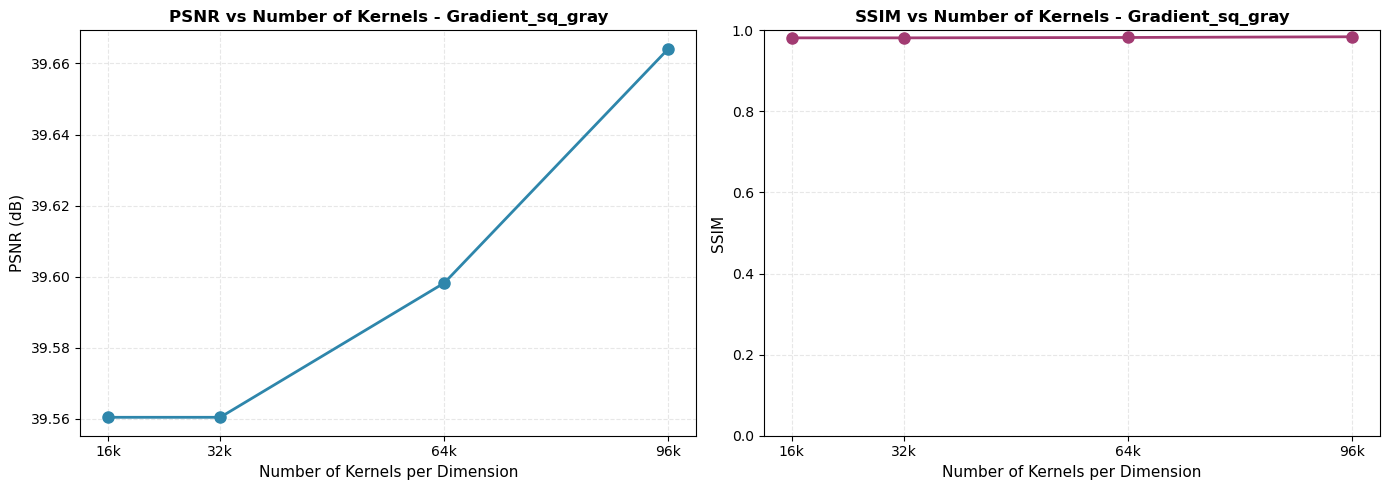

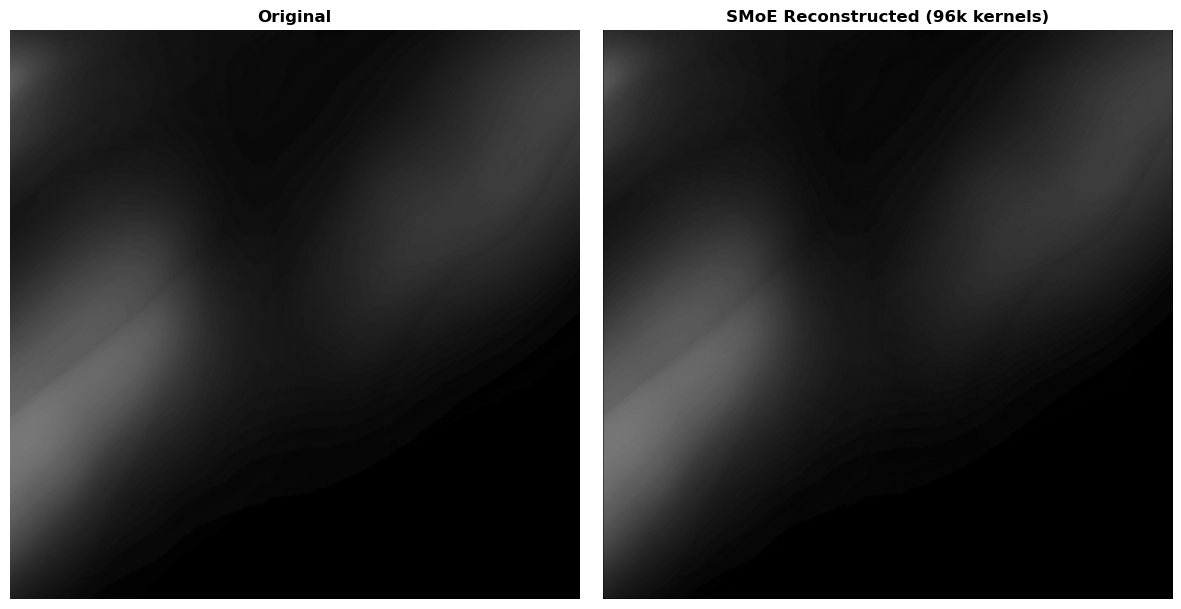


Processing: Grass_sq_gray
Loaded original: c:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Code\Final\SMoE\16k_100i_3535s\tf-smoe-master\data\Grass_sq_gray.png with shape (1274, 1274)
16k: PSNR=22.09 dB, SSIM=0.7773
16k: PSNR=22.09 dB, SSIM=0.7773
32k: PSNR=22.09 dB, SSIM=0.7773
32k: PSNR=22.09 dB, SSIM=0.7773
64k: PSNR=25.85 dB, SSIM=0.8963
64k: PSNR=25.85 dB, SSIM=0.8963
96k: PSNR=31.33 dB, SSIM=0.9723
96k: PSNR=31.33 dB, SSIM=0.9723


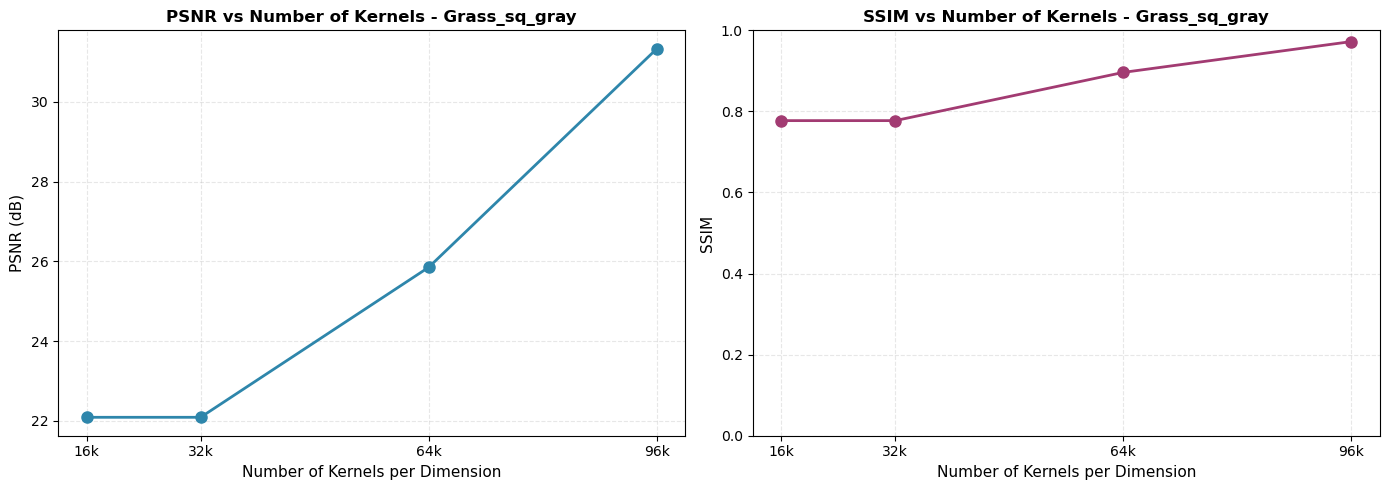

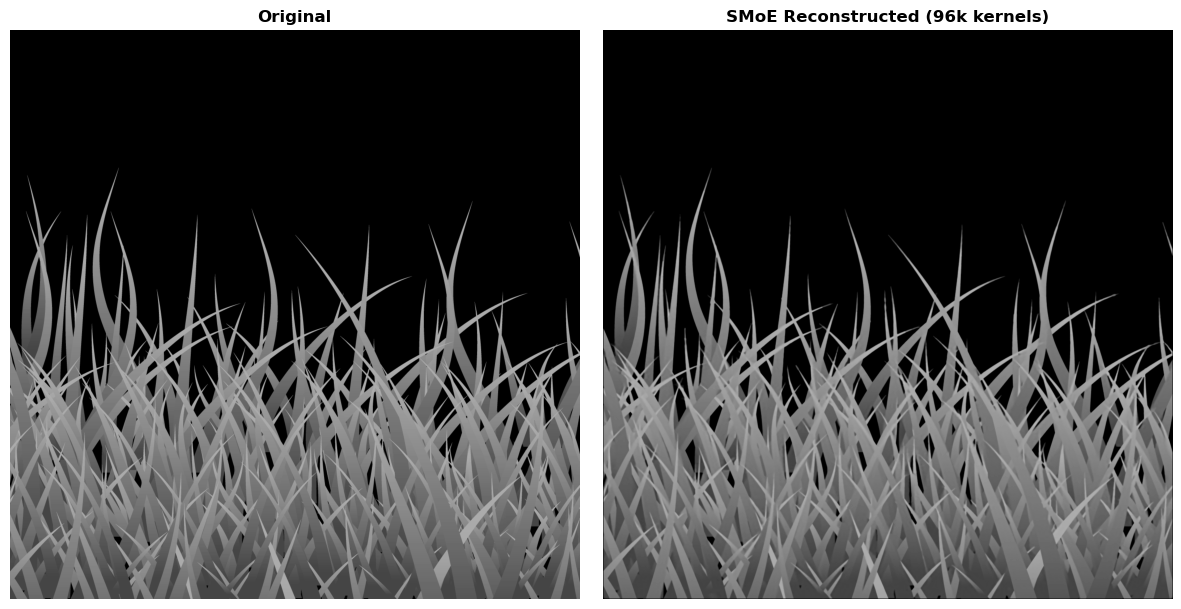


Processing: Mixed_sq_gray
Loaded original: c:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Code\Final\SMoE\16k_100i_3535s\tf-smoe-master\data\Mixed_sq_gray.png with shape (2300, 2300)
16k: PSNR=23.07 dB, SSIM=0.7637
16k: PSNR=23.07 dB, SSIM=0.7637
32k: PSNR=23.07 dB, SSIM=0.7637
32k: PSNR=23.07 dB, SSIM=0.7637
64k: PSNR=28.08 dB, SSIM=0.9230
64k: PSNR=28.08 dB, SSIM=0.9230


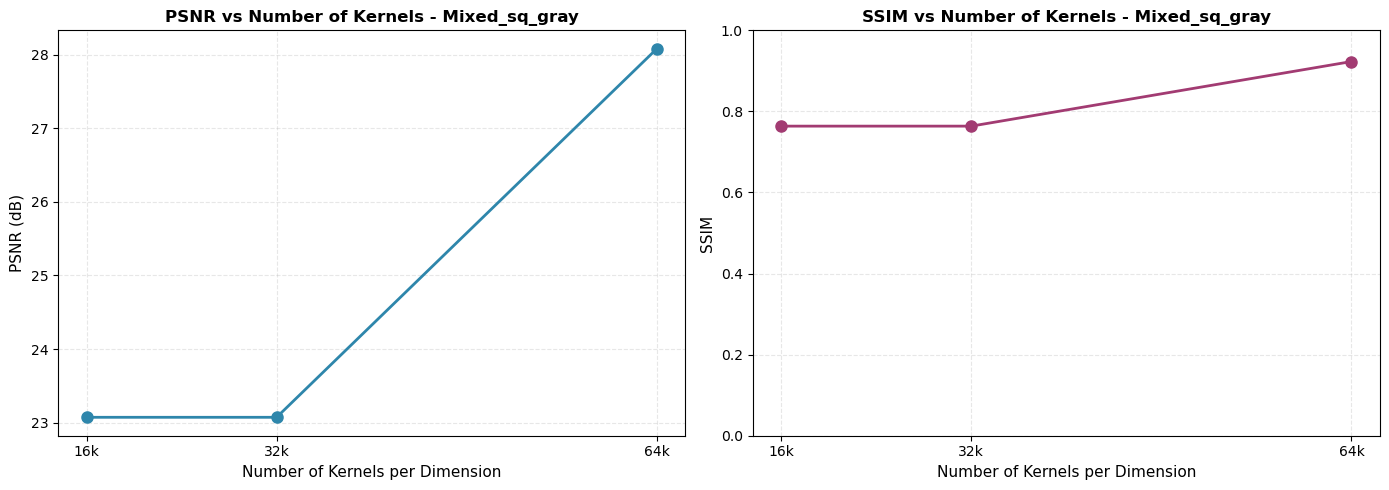

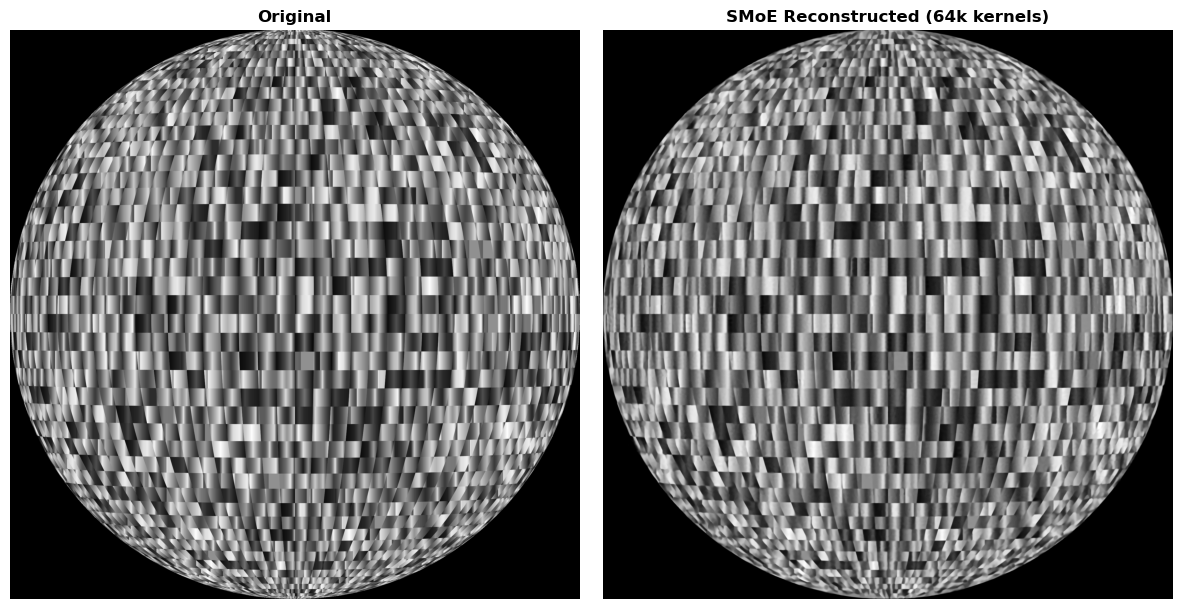


Processing: Nature_sq_gray
Loaded original: c:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Code\Final\SMoE\16k_100i_3535s\tf-smoe-master\data\Nature_sq_gray.png with shape (1200, 1200)
16k: PSNR=20.84 dB, SSIM=0.4798
16k: PSNR=20.84 dB, SSIM=0.4798
32k: PSNR=20.84 dB, SSIM=0.4798
32k: PSNR=20.84 dB, SSIM=0.4798
64k: PSNR=22.13 dB, SSIM=0.5988
64k: PSNR=22.13 dB, SSIM=0.5988
96k: PSNR=24.73 dB, SSIM=0.8056
96k: PSNR=24.73 dB, SSIM=0.8056


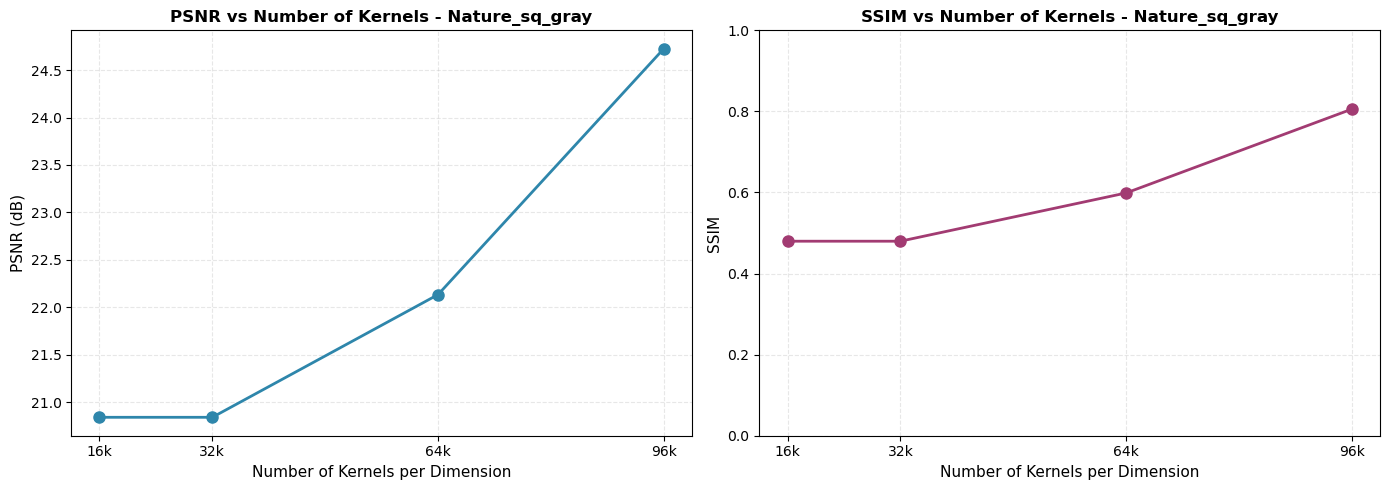

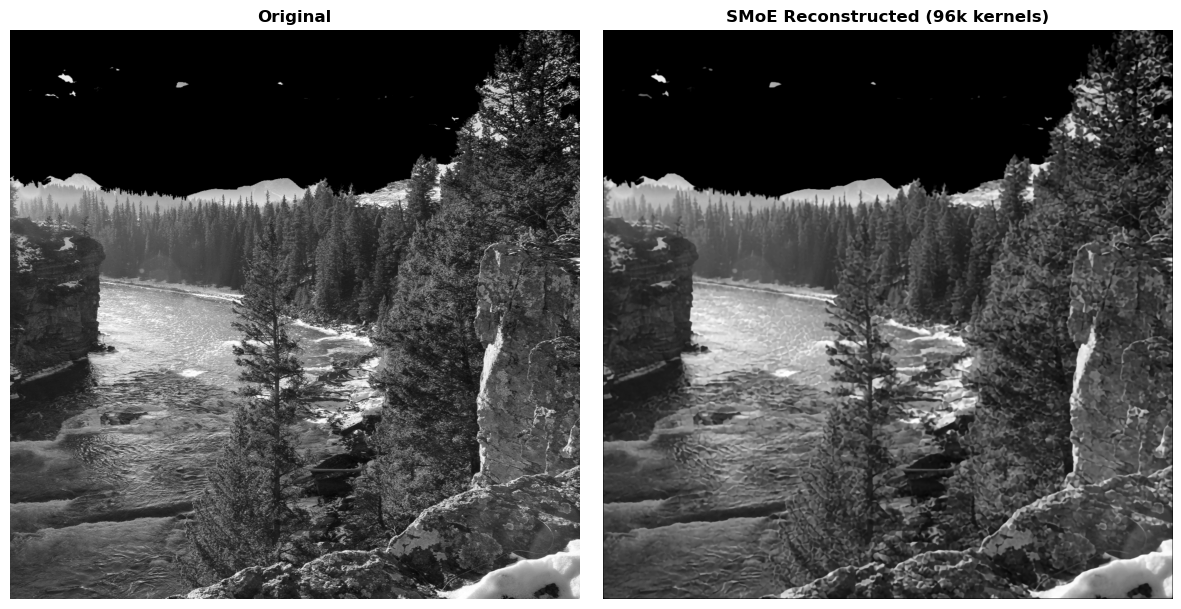


Processing: SharpEdges_sq_gray
Loaded original: c:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Code\Final\SMoE\16k_100i_3535s\tf-smoe-master\data\SharpEdges_sq_gray.png with shape (1486, 1486)
16k: PSNR=30.92 dB, SSIM=0.9588
16k: PSNR=30.92 dB, SSIM=0.9588
32k: PSNR=30.92 dB, SSIM=0.9588
32k: PSNR=30.92 dB, SSIM=0.9588
64k: PSNR=33.07 dB, SSIM=0.9823
64k: PSNR=33.07 dB, SSIM=0.9823
96k: PSNR=34.33 dB, SSIM=0.9909
96k: PSNR=34.33 dB, SSIM=0.9909


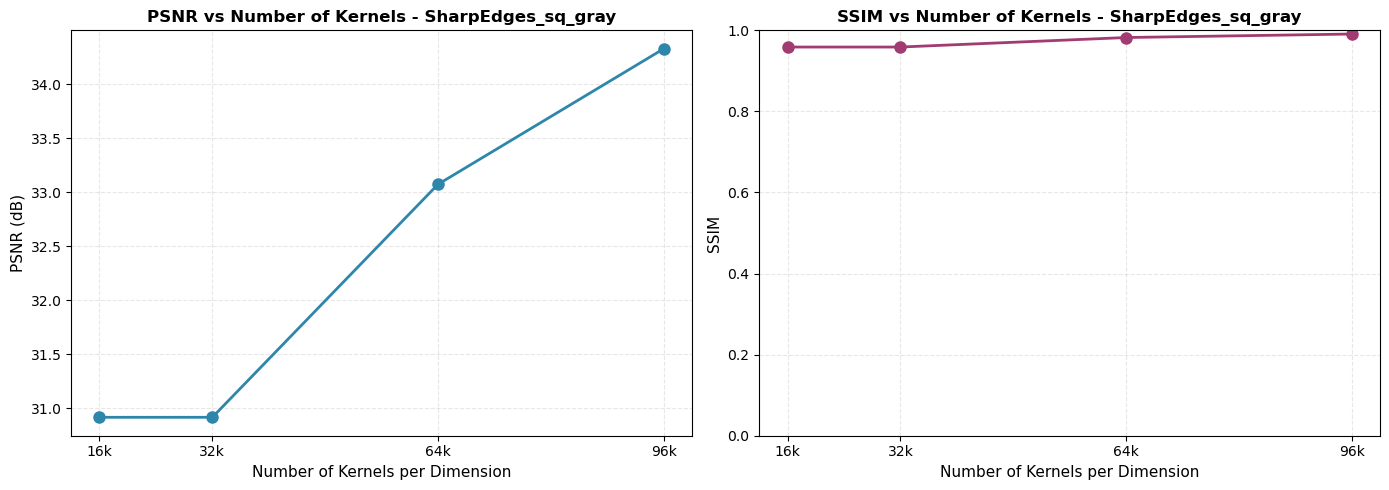

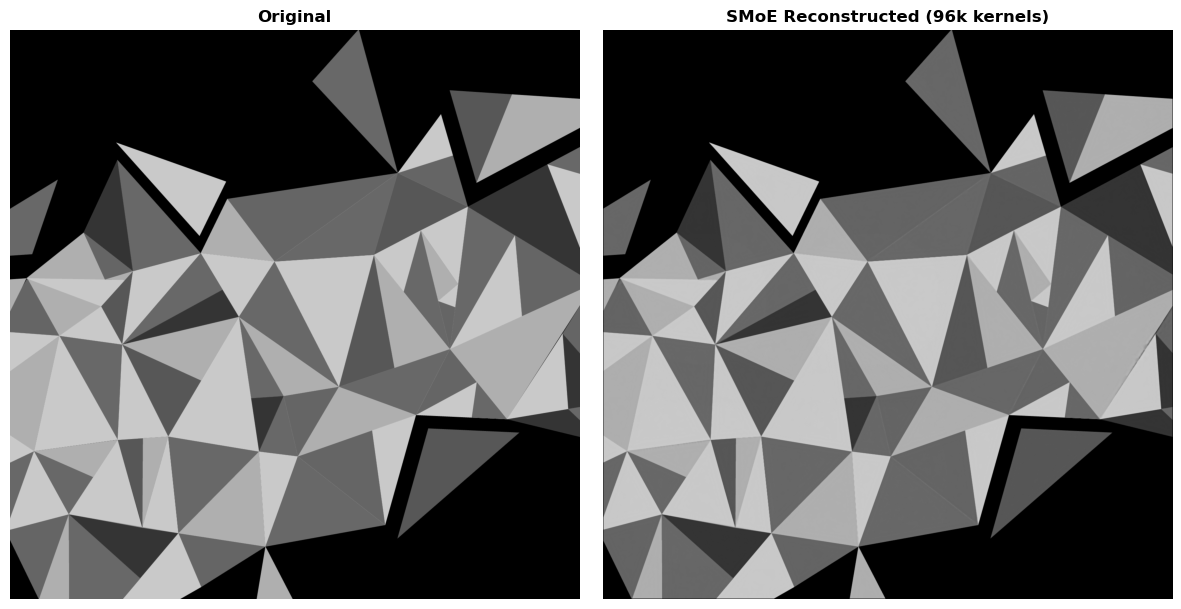


SMoE Quality Analysis Complete!


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread
from pathlib import Path
import os

# --- PSNR / SSIM calculation functions (same as JPEG.ipynb) ---
def psnr(img1, img2, data_range=255.0):
    x = img1.astype(np.float64)
    y = img2.astype(np.float64)
    mse = np.mean((x - y) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(data_range) - 10 * np.log10(mse)

def _box_filter_same(img, w):
    if img.ndim == 2:
        img = img[..., None]
        squeeze = True
    else:
        squeeze = False
    pad = w // 2
    img_p = np.pad(img, ((pad, pad), (pad, pad), (0, 0)), mode='reflect')
    tmp = np.cumsum(img_p, axis=0)
    tmp = tmp[w:, :, :] - tmp[:-w, :, :]
    tmp2 = np.cumsum(tmp, axis=1)
    res = tmp2[:, w:, :] - tmp2[:, :-w, :]
    res = res / (w * w)
    if squeeze:
        return res[..., 0]
    return res

def ssim(img1, img2, data_range=255.0, win_size=11, K1=0.01, K2=0.03):
    x = img1.astype(np.float64)
    y = img2.astype(np.float64)
    C1 = (K1 * data_range) ** 2
    C2 = (K2 * data_range) ** 2
    mu_x = _box_filter_same(x, win_size)
    mu_y = _box_filter_same(y, win_size)
    sigma_x2 = _box_filter_same(x * x, win_size) - mu_x * mu_x
    sigma_y2 = _box_filter_same(y * y, win_size) - mu_y * mu_y
    sigma_xy = _box_filter_same(x * y, win_size) - mu_x * mu_y
    num = (2 * mu_x * mu_y + C1) * (2 * sigma_xy + C2)
    den = (mu_x * mu_x + mu_y * mu_y + C1) * (sigma_x2 + sigma_y2 + C2)
    ssim_map = num / (den + 1e-12)
    return float(np.mean(ssim_map))

# --- Configuration ---
# Define the kernel configurations (representing different "quality" levels)
kernel_configs = [
    {'name': '16k_100i_3535s', 'kernels': 16, 'label': '16k'},
    {'name': '32k_100i_7899s', 'kernels': 32, 'label': '32k'},
    {'name': '64k_100i_25201s', 'kernels': 64, 'label': '64k'},
    {'name': '96k_100i_43212s', 'kernels': 96, 'label': '96k'},
]

# Image names (without extensions)
image_names = ['Gradient_sq_gray', 'Grass_sq_gray', 'Mixed_sq_gray', 'Nature_sq_gray', 'SharpEdges_sq_gray']

# Base path to the SMoE folders
base_smoe_path = Path(r'c:\Users\Leonardo\Documents\Università\Erasmus\Subjects\Quantitative Research\Project\Code\Final\SMoE')

# --- Process each image ---
for img_name in image_names:
    print('\n' + '='*60)
    print(f"Processing: {img_name}")
    print('='*60)
    
    # Load original image from the first kernel config folder (they should all have the same original)
    orig_found = False
    for config in kernel_configs:
        # Try to find original in data/tiles folder
        tiles_folder = base_smoe_path / config['name'] / 'tf-smoe-master' / 'data' / 'tiles' / img_name
        if tiles_folder.exists():
            # Get the first tile to reconstruct or use any tile as reference
            tile_files = list(tiles_folder.glob('*.png'))
            if tile_files:
                # Actually, we need the full original image, let's check if there's a reconstructed version
                # The original should be in the parent data folder
                orig_path = base_smoe_path / config['name'] / 'tf-smoe-master' / 'data' / f'{img_name}.png'
                if orig_path.exists():
                    orig_found = True
                    break
    
    if not orig_found:
        print(f"WARNING: Could not find original image for {img_name}, skipping...")
        continue
    
    # Read original
    try:
        orig = imread(str(orig_path))
        # Convert to grayscale if needed
        if orig.ndim == 3:
            orig = (0.299 * orig[..., 0] + 0.587 * orig[..., 1] + 0.114 * orig[..., 2]).astype(np.uint8)
        elif orig.dtype != np.uint8:
            orig = (orig * 255).clip(0, 255).astype(np.uint8)
        print(f"Loaded original: {orig_path} with shape {orig.shape}")
    except Exception as e:
        print(f"ERROR loading original {orig_path}: {e}")
        continue
    
    psnr_values = []
    ssim_values = []
    kernel_labels = []
    
    # Compute metrics for each kernel configuration
    for config in kernel_configs:
        # Path to reconstructed image
        recon_path = base_smoe_path / config['name'] / 'tf-smoe-master' / 'results' / f"{img_name}_reconstructed.png"
        
        if not recon_path.exists():
            print(f"WARNING: Reconstructed image not found at {recon_path}")
            psnr_values.append(None)
            ssim_values.append(None)
        else:
            try:
                # Load reconstructed image
                recon = imread(str(recon_path))
                
                # Convert to grayscale if needed
                if recon.ndim == 3:
                    recon = (0.299 * recon[..., 0] + 0.587 * recon[..., 1] + 0.114 * recon[..., 2]).astype(np.uint8)
                elif recon.dtype != np.uint8:
                    recon = (recon * 255).clip(0, 255).astype(np.uint8)
                
                # Ensure same size
                if orig.shape != recon.shape:
                    print(f"WARNING: Shape mismatch for {config['label']}: orig {orig.shape} vs recon {recon.shape}")
                    # Crop to match
                    min_h = min(orig.shape[0], recon.shape[0])
                    min_w = min(orig.shape[1], recon.shape[1])
                    orig_crop = orig[:min_h, :min_w]
                    recon_crop = recon[:min_h, :min_w]
                else:
                    orig_crop = orig
                    recon_crop = recon
                
                # Calculate metrics
                psnr_val = psnr(orig_crop, recon_crop)
                ssim_val = ssim(orig_crop, recon_crop)
                
                psnr_values.append(psnr_val)
                ssim_values.append(ssim_val)
                
                print(f"{config['label']}: PSNR={psnr_val:.2f} dB, SSIM={ssim_val:.4f}")
            except Exception as e:
                print(f"ERROR processing {config['label']}: {e}")
                psnr_values.append(None)
                ssim_values.append(None)
        
        kernel_labels.append(config['label'])
    
    # Filter out None values for plotting
    valid_indices = [i for i, v in enumerate(psnr_values) if v is not None]
    if not valid_indices:
        print(f"No valid data to plot for {img_name}")
        continue
    
    kernels_plot = [kernel_configs[i]['kernels'] for i in valid_indices]
    labels_plot = [kernel_labels[i] for i in valid_indices]
    psnr_plot = [psnr_values[i] for i in valid_indices]
    ssim_plot = [ssim_values[i] for i in valid_indices]
    
    # Plot PSNR and SSIM vs number of kernels
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    
    ax[0].plot(kernels_plot, psnr_plot, marker='o', linewidth=2, markersize=8, color='#2E86AB')
    ax[0].set_title(f'PSNR vs Number of Kernels - {img_name}', fontsize=12, fontweight='bold')
    ax[0].set_xlabel('Number of Kernels per Dimension', fontsize=11)
    ax[0].set_ylabel('PSNR (dB)', fontsize=11)
    ax[0].grid(True, alpha=0.3, linestyle='--')
    ax[0].set_xticks(kernels_plot)
    ax[0].set_xticklabels(labels_plot)
    
    ax[1].plot(kernels_plot, ssim_plot, marker='o', color='#A23B72', linewidth=2, markersize=8)
    ax[1].set_title(f'SSIM vs Number of Kernels - {img_name}', fontsize=12, fontweight='bold')
    ax[1].set_xlabel('Number of Kernels per Dimension', fontsize=11)
    ax[1].set_ylabel('SSIM', fontsize=11)
    ax[1].set_ylim(0, 1.0)
    ax[1].grid(True, alpha=0.3, linestyle='--')
    ax[1].set_xticks(kernels_plot)
    ax[1].set_xticklabels(labels_plot)
    
    plt.tight_layout()
    plt.show()
    
    # Display original vs best reconstruction
    if valid_indices:
        best_idx = valid_indices[-1]  # Highest kernel count
        best_config = kernel_configs[best_idx]
        recon_path = base_smoe_path / best_config['name'] / 'tf-smoe-master' / 'results' / f"{img_name}_reconstructed.png"
        
        if recon_path.exists():
            recon_best = imread(str(recon_path))
            if recon_best.ndim == 3:
                recon_best = (0.299 * recon_best[..., 0] + 0.587 * recon_best[..., 1] + 0.114 * recon_best[..., 2]).astype(np.uint8)
            
            fig2, ax2 = plt.subplots(1, 2, figsize=(12, 6))
            ax2[0].imshow(orig, cmap='gray', vmin=0, vmax=255)
            ax2[0].set_title('Original', fontsize=12, fontweight='bold')
            ax2[0].axis('off')
            ax2[1].imshow(recon_best, cmap='gray', vmin=0, vmax=255)
            ax2[1].set_title(f'SMoE Reconstructed ({best_config["label"]} kernels)', fontsize=12, fontweight='bold')
            ax2[1].axis('off')
            plt.tight_layout()
            plt.show()

print('\n' + '='*60)
print('SMoE Quality Analysis Complete!')
print('='*60)